# Experiment 9: Iris Classification with a Decision Tree

Train and evaluate a depth-limited decision tree using scikit-learn's built-in Iris dataset.

## Decision tree preview
The embedded diagram is a schematic preview; running the notebook generates the actual fitted tree and saves it as `experiment_09_decision_tree.png`.

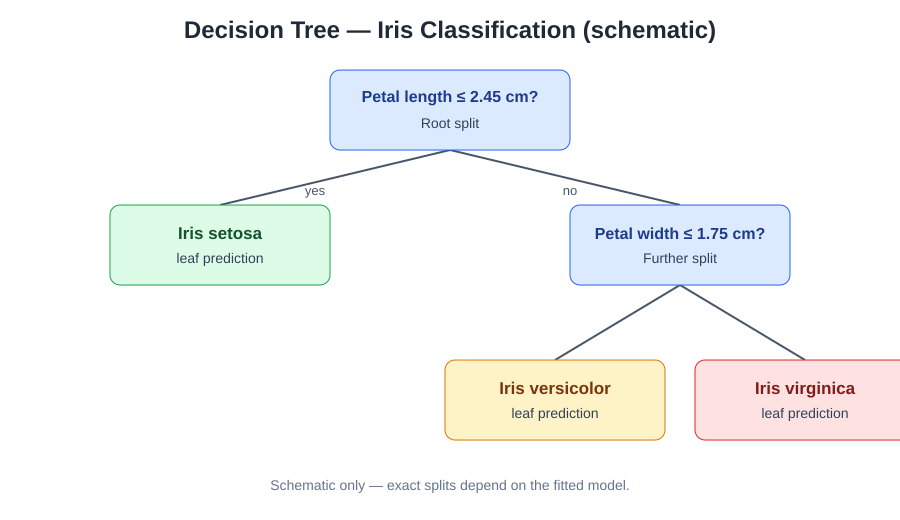

In [ ]:
# Decision tree image preview (schematic; fitted tree appears when run)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load the built-in Iris dataset directly to avoid FileNotFoundError
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['Species'] = iris.target

# Map target integers back to species names for readability
species_map = {i: name for i, name in enumerate(iris.target_names)}
df['Species'] = df['Species'].map(species_map)

print(df.head())
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print(df["Species"].value_counts())
  
# Prepare features and target
X = df.drop(["Species"], axis=1)
y = df["Species"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)
print("Classification Report:\n", classification_report(y_test, y_pred))

plt.figure(figsize=(14, 8))
plot_tree(model, feature_names=X.columns, class_names=model.classes_, filled=True, rounded=True)
plt.title("Decision Tree - Iris Dataset")
plt.savefig('experiment_09_decision_tree.png', dpi=160, bbox_inches='tight')
plt.show()